<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving house_prices.csv to house_prices.csv
DATASET:
    Area  Bedrooms  Age  Distance  Price_Lakhs
0    600         1   20         8           25
1    800         2   15         7           35
2    900         2   10         6           42
3   1000         2    8         5           50
4   1100         2    5         5           58
5   1200         3   10         4           65
6   1300         3    8         4           72
7   1400         3    5         3           82
8   1500         3    4         3           90
9   1600         3    2         2          105
10  1700         3    5         2          112
11  1800         4    3         3          120
12  1900         4    2         2          135
13  2000         4    1         2          150
14   750         1   18         9           28
15   950         2   12         7           40
16  1250         3    7         5           68
17  1450         3    6         4           80
18  1650         3    3         3          108
19  185

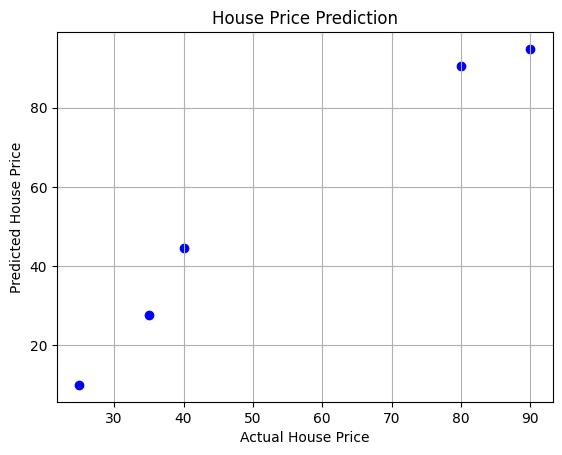

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("DATASET:")
print(data)

# Input features
X = data[[
    "Area",
    "Bedrooms",
    "Age",
    "Distance"
]]

# Target variable
y = data["Price_Lakhs"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Create Linear Regression model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

print("\nActual House Prices:")
print(y_test.values)

print("\nPredicted House Prices:")
print(y_pred)

# Evaluation
print("\nMean Absolute Error:")
print(mean_absolute_error(y_test, y_pred))

print("\nMean Squared Error:")
print(mean_squared_error(y_test, y_pred))

print("\nR2 Score:")
print(r2_score(y_test, y_pred))

# Predict new house price
new_house = pd.DataFrame({
    "Area": [1500],
    "Bedrooms": [3],
    "Age": [5],
    "Distance": [4]
})

price = model.predict(new_house)

print("\nPredicted House Price:")
print(price[0], "Lakhs")

# Plot graph
plt.scatter(y_test, y_pred, color="blue")

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("House Price Prediction")

plt.grid()
plt.show()